# Detecting the anomalous activity of a ship’s engine


The work outlined here has been originally submitted as a project for the CAM PACE DS P1 26 Programme.


## **Business context**
A real data set has been provided to identify anomalous activity in a ship’s engine functionality (Devabrat,  2022). Typically speaking, anomalies would make up a minority of the data points (i.e., about 1% to 5% of the data points would be anomalies).

The data set contains six important features continuously monitored to evaluate the engine's status as ‘good’ or ‘bad’. These features are:
- **Engine rpm (revolutions per minute):** A high rpm indicates the engine is operating at a higher speed than designed for prolonged periods, which can lead to overheating, excessive wear, and eventual failure. A low rpm could signal a lack of power, issues with fuel delivery, or internal mechanical problems.
- **Lubrication oil pressure:** Low lubrication oil pressure indicates insufficient lubrication, leading to increased friction, overheating, and engine damage. A high lubrication oil pressure could signal a blockage in the oil delivery system, potentially causing seal or gasket failure.
- **Fuel pressure:** High fuel pressure can cause poor engine performance and incomplete combustion, indicating fuel pump or filter issues. A low fuel pressure may result in excessive fuel consumption, poor emissions, or damage to the fuel injectors.
- **Coolant pressure:** Low coolant pressure indicates a potential leak in the cooling system or a coolant pump failure, risking engine overheating. A high coolant pressure could be a sign of a blockage in the cooling system or a failing head gasket, which can also lead to overheating.
- **Lubrication oil temperature:** High lubrication oil temperature suggests the oil is overheating, which can degrade its lubricating properties and lead to engine damage. A low lubrication oil temperature may indicate it is not reaching its optimal operating temperature, potentially causing inadequate lubrication.
- **Coolant temperature:** High coolant temperature signals overheating, which various issues, including a failed thermostat, coolant leak, or insufficient coolant flow can cause. A low coolant temperature could suggest the engine is not reaching its optimal operating temperature, affecting performance and efficiency.

Issues with engines could lead to engine malfunctions, potential safety hazards, and downtime (e.g. delayed deliveries), resulting in the breakdown of a ship’s overall functionality, consequently impacting the business, such as affecting revenue via failure to deliver goods. By predicting timely maintenance, the business aims to increase profit by reducing downtime, reducing safety risks for the crew, limiting fuel consumption, and increasing customer satisfaction through timely deliveries.

The task is to develop a robust anomaly detection system to protect a company’s shipping fleet by evaluating engine functionality. Therefore, we’ll explore the data and:
- employ preprocessing and feature engineering
- perform anomaly detection.



> **Disclaimer**
>
> Please note that although a real-life data set was provided, the business context in this project is fictitious. Any resemblance to companies and persons (living or dead) is coincidental.




## 1.Exploratory Data Analysis (EDA)

### 1.1 Import the relevant libraries and load the dataset:




In [ ]:
# Import the necessary libraries.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files
import time
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA



In [ ]:
# URL to import data set from GitHub.
url = 'https://raw.githubusercontent.com/fourthrevlxd/cam_dsb/main/engine.csv'

### 1.2 Initial look at the dataset:

In [ ]:
df = pd.read_csv(url)
print(df.shape)
df.head()


(19535, 6)


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp
0,682,2.391656,4.617196,2.848982,76.272417,69.884609
1,605,5.466877,6.424361,5.727520,73.222679,74.907314
2,658,3.434232,3.680896,1.678708,88.089916,78.704806
3,749,2.094656,7.120927,1.639670,77.661625,82.386700
4,676,3.538228,5.956472,3.225336,75.226352,67.153220


### 1.3 Check for missing values:

---



In [ ]:

df.isnull().sum()

,0
Engine rpm,0
Lub oil pressure,0
Fuel pressure,0
Coolant pressure,0
lub oil temp,0
Coolant temp,0


### 1.4 Check for duplicates:

In [ ]:
df[df.duplicated()]

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp


The dataset is composed of numerical columns, is void of duplicates and contains no missing values which eliminates the need for encoding and imputing processes.

### 1.5 Compute descriptive statistics:

In [ ]:
df.describe()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp
count,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000
mean,791.239263,3.303775,6.655615,2.335369,77.643420,78.427433
std,267.611193,1.021643,2.761021,1.036382,3.110984,6.206749
min,61.000000,0.003384,0.003187,0.002483,71.321974,61.673325
25%,593.000000,2.518815,4.916886,1.600466,75.725990,73.895421
50%,746.000000,3.162035,6.201720,2.166883,76.817350,78.346662
75%,934.000000,4.055272,7.744973,2.848840,78.071691,82.915411
max,2239.000000,7.265566,21.138326,7.478505,89.580796,195.527912


Based on the standard deviation as well as the min-max values listed for each feature, we observe a significant level of variablity across the 6 features. For instance, while 'Engine rpm' ranges from 61 to 2239, 'Lubricant oil pressure' ranges from 0.00 to 7.26. Therefore, feature scaling may be necessary to ensure features have a consistent range, especially before applying techniques that incorporate local distances.

### 1.6 Observe the mean and median for each feature:

In [ ]:
df.agg(['mean', 'median'])


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp
mean,791.239263,3.303775,6.655615,2.335369,77.64342,78.427433
median,746.000000,3.162035,6.201720,2.166883,76.81735,78.346662


For all the features, the means computed do not equal the median values which could be signalling the presence of outliers and/or asymmetry in distribution patterns.

### 1.7 Visualise the data to determine the distribution and extreme values:

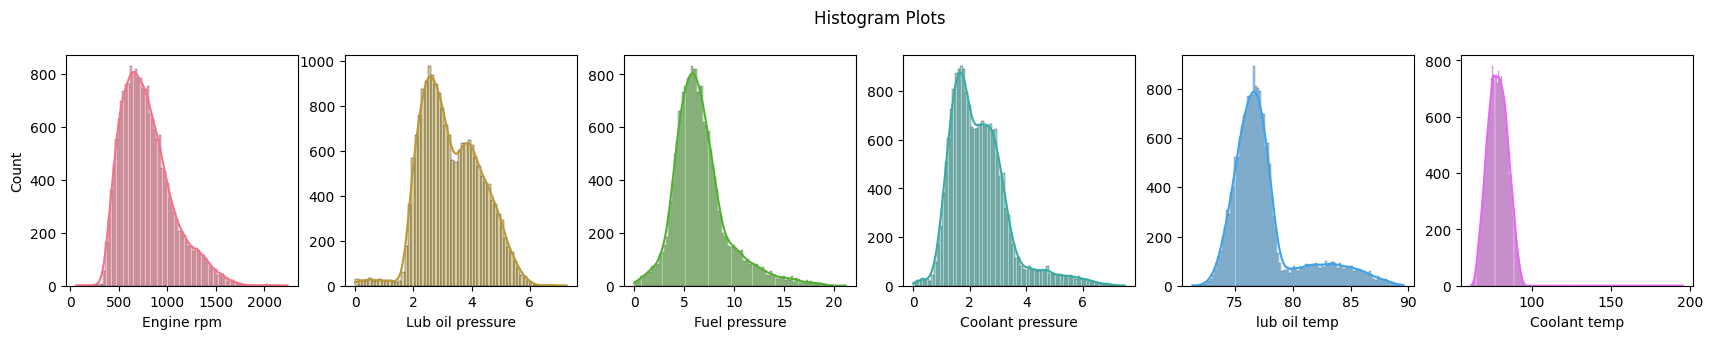

In [ ]:
# Create histograms to see distribution of the features.

fig, axes = plt.subplots(1, 6, figsize=(21, 3))
palette1 = iter(sns.husl_palette(6))
for i,col in enumerate(df.columns):
  sns.histplot(df[col], ax=axes[i], color=next(palette1),kde=True)

plt.setp(axes, ylabel="")
axes[0].set_ylabel('Count')
plt.title('Histogram Plots', x=-2.5, y=1.1)
plt.show()


The histogram plots obtained for each feature indicate none of the features fall under a normal distribution. The 'coolant temperature' distribution is right-skewed whereas multi-modality is present for remainder of the features studied, albeit at varying degrees.

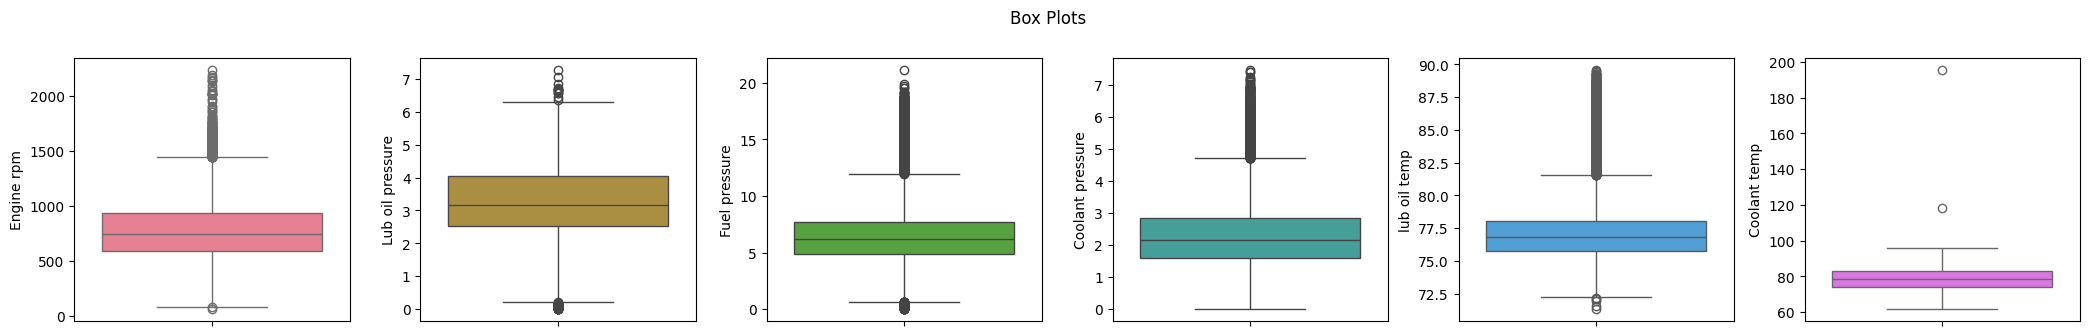

In [ ]:
# Create boxplots to visualise the spread of outliers per feature.
fig, axes = plt.subplots(1, 6, figsize=(21, 3))
palette1 = iter(sns.husl_palette(6))
for i,col in enumerate(df.columns):
 sns.boxplot(y=df[col], ax=axes[i],color=next(palette1))

plt.tight_layout()
plt.title('Box Plots', x=-2.75, y=1.1)
#plt.savefig("boxplots.svg")
plt.show()

The box plots produced for each feature show several datapoints exist beyond the maximum interquartile range (i.e. outside the whiskers). The percentage of datapoints that lie above the maximum (upper whisker) are significantly higher compared to those below the minimum (lower whisker). The 'coolant temperature' is the only feature which does not display a significant percentage of outliers.

## 2.Anomaly Detection with IQR Method

The IQR method is applicable to data that does not follow a normal distribution and is easy to interpret: the box in the box plot gives a visual representation of the interquartile range itself.

### 2.1 Identify outliers for each feature:

In [ ]:
# Sort values in ascending order
sorted=df.apply(lambda x: x.sort_values().values)

# Next create a new dataframe with sorted columns added to capture outliers detected per feature
new_df=df.copy()


In [ ]:
# Create another dataframe to get parameters used in IQR calculations to be displayed as a table
table_IQR=pd.DataFrame(columns=[sorted.columns], index=['q1','q3','IQR','lower bound','upper bound'])

# The IQR approach
for col in sorted.columns:

  # Calculate the quantiles
  q1 = sorted[col].quantile(0.25)
  q3 = sorted[col].quantile(0.75)
  # Add to table
  table_IQR.loc['q1',col] = q1
  table_IQR.loc['q3',col] = q3

  # Compute the IQR.
  iqr = q3 - q1
  # Add to table
  table_IQR.loc['IQR',col] = iqr

  # Calculate the upper and lower limits
  lower = q1-1.5*iqr
  upper = q3+1.5*iqr
  # Add to table
  table_IQR.loc['lower bound',col] = lower
  table_IQR.loc['upper bound',col] = upper

  # Assign a new column per existing feature for capturing outliers
  col_name=col+'_flagged'
  new_df[col_name]=(new_df[col] < lower) | (new_df[col] > upper)

  # Convert booleans to integers.
  new_df[col_name] = new_df[col_name].astype(int)






In [ ]:
# The table output
display(table_IQR)


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp
q1,593.0,2.518815,4.916886,1.600466,75.72599,73.895421
q3,934.0,4.055272,7.744973,2.84884,78.071691,82.915411
IQR,341.0,1.536457,2.828087,1.248374,2.3457,9.01999
lower bound,81.5,0.21413,0.674755,-0.272095,72.20744,60.365435
upper bound,1445.5,6.359957,11.987104,4.7214,81.590241,96.445397


The table gives a list of the parameters computer for each feature and implemented in the IQR approach.

### 2.2 Create a new column per feature that will indicate in binary, if the value of that feature is an outlier based on IQR calculations:

In [ ]:
# Randomly sampled dataset
display(new_df.sample(n=5))


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine rpm_flagged,Lub oil pressure_flagged,Fuel pressure_flagged,Coolant pressure_flagged,lub oil temp_flagged,Coolant temp_flagged
7694,683,1.942557,4.456400,1.976993,83.443898,67.704208,0,0,0,0,1,0
8382,1203,4.412092,6.611722,1.683417,76.115144,79.879125,0,0,0,0,0,0
15958,599,4.176450,6.166926,1.695992,78.417948,77.691869,0,0,0,0,0,0
11405,493,3.023961,4.381602,2.789675,81.369553,78.576896,0,0,0,0,0,0
1157,697,4.687148,6.026641,2.000057,75.256694,82.644599,0,0,0,0,0,0


The IQR approach inevitably increases feature dimensionality by adding one column per feature which is far from ideal when working with a high-dimensional dataset.

### 2.3 Identify the number of features that must simultaneously be flagged as potential outliers, in order for a sample to be classified as a true outlier, such that the total outlier percentage falls within the 1-5% range:

In [ ]:
# Get the accumulative sum of outlier flags (1s and 0s) for each feature
flag_cols = [col for col in new_df.columns if '_flagged' in col]
for col in flag_cols:
  flag_sum=new_df[col].sum()
  flag_percentage=flag_sum/len(new_df)
  print(col + ':', flag_sum,'(',round(flag_percentage*100, 2), '%)')

Engine rpm_flagged: 464 ( 2.38 %)
Lub oil pressure_flagged: 66 ( 0.34 %)
Fuel pressure_flagged: 1135 ( 5.81 %)
Coolant pressure_flagged: 785 ( 4.02 %)
lub oil temp_flagged: 2617 ( 13.4 %)
Coolant temp_flagged: 2 ( 0.01 %)


The results are consistent with the box plots where the highest density of outliers are observed for features including 'lubricant oil tempereture', 'fuel pressure' and 'coolant pressure'- whereas the lowest number of outliers are observed for the 'coolant temperature'.

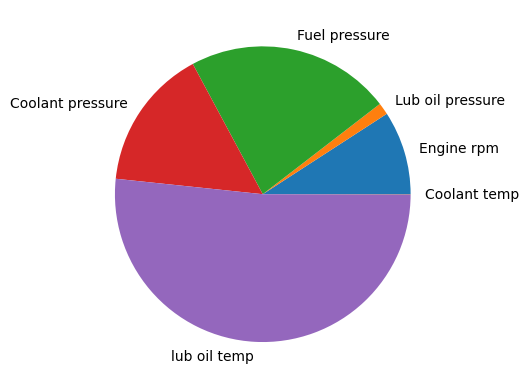

In [ ]:
# Present the results in a pie chart
P= np.array([464, 66, 1135, 785,2617,2])


plt.pie(P, labels = df.columns)
#plt.savefig("pie.svg")
plt.show()


It is important to note that datapoints individually flagged as outliers does not necessarily indicate an anomaly in the state of the engine, and it may be necessary to observe these outliers simultaneously occuring for different features. To explore what constitutes a true outlier or an anomaly, the total outlier percentage has been computed for a different set of scenarios where one or more feature(s) were flagged.

In [ ]:
# Identify which observations have ﬂagged columns (1s) in at least one feature or more

# Getting the flag count row-wise
for i in range(len(new_df)):
    count = new_df.loc[i,flag_cols].sum()
    # Add new column 'Flag Count' to give total count per data entry
    new_df.loc[i,'Flag Count']=count


In [ ]:
# Extract and print the total flag count for a set of scenarios
for i in range(1,6):
  flag_count=len(new_df[new_df['Flag Count'] == i])
  flag_percentage=(flag_count/len(new_df))*100
  print('total outlier count with', i ,'feature(s) flagged', ':', flag_count, '(', round(flag_percentage,2), '%)')


total outlier count with 1 feature(s) flagged : 4214 ( 21.57 %)
total outlier count with 2 feature(s) flagged : 411 ( 2.1 %)
total outlier count with 3 feature(s) flagged : 11 ( 0.06 %)
total outlier count with 4 feature(s) flagged : 0 ( 0.0 %)
total outlier count with 5 feature(s) flagged : 0 ( 0.0 %)


The percentages obtained for each scenario considered show that **only when two features are flagged simultaneously**, the total anomaly percentage meets the expected range of 1-5%. In other words, out of the 19535 datapoints, 411 entries recorded indicate a potential problem with the ship's engine.

## 3.Anomaly Detection Using One-Class SVM



### 3.1 Apply feature scaling and identify possible anomalies:

In [ ]:
# Scale data for better SVM performance
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

Because standardisation does not impose any bounds on the feature values, it is
ideal to use for datasets containing outliers.

In [ ]:
# Check the output
df_scaled

array([[-0.40821185, -0.89281929, -0.73830371,  0.49559555, -0.44070891,
        -1.37641176],
       [-0.69595007,  2.11733175, -0.08375911,  3.27315389, -1.42104681,
        -0.56715821],
       [-0.49789649,  0.12769669, -1.07742594, -0.63362488,  3.35802552,
         0.04469003],
       ...,
       [-0.65484461,  0.00614053, -1.03874489,  3.53706979, -0.56369786,
        -1.00013427],
       [ 1.38921787, -0.55994531, -1.06920452,  0.59469502, -0.27605939,
         0.47895143],
       [-0.35963266, -0.77199786, -0.10871387,  0.34080808, -0.02812746,
        -1.17155345]])

In [ ]:
# Start with a pre-defined One-Class SVM model
model = OneClassSVM(kernel='rbf', gamma=0.5, nu=0.05)
model.fit(df_scaled)

OneClassSVM(gamma=0.5, nu=0.05)

In [ ]:
# Predict the class (normal or anomaly).
y_pred = model.predict(df_scaled)
print(y_pred)

[ 1 -1  1 ...  1  1  1]


* Using one-class SVM with a radial basis function (RBF), the dataset is  mapped onto a hyperplane which serves as a decision boundary.
* Based on the distance that data points fall from the hyperplane, they are either marked as normal (inside the boundary) or as anomalies (outside the boundary).
* The result is a set of labels which are stored by the outcome variable, y_pred as -1s for anomalies and as 1s for normal data points.


In [ ]:
# Create a new dataframe with the scaled feature columns and the anomaly predictions

df_SVM=pd.DataFrame(df_scaled, columns=df.columns)
df_SVM['anomaly'] = y_pred

df_SVM

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,anomaly
0,-0.408212,-0.892819,-0.738304,0.495596,-0.440709,-1.376412,1
1,-0.695950,2.117332,-0.083759,3.273154,-1.421047,-0.567158,-1
2,-0.497896,0.127697,-1.077426,-0.633625,3.358026,0.044690,1
3,-0.157842,-1.183534,0.168533,-0.671293,0.005852,0.637913,1
4,-0.430633,0.229492,-0.253226,0.858747,-0.776966,-1.816491,1
...,...,...,...,...,...,...,...
19530,-0.411949,0.288774,0.233701,-1.208058,-0.461752,-1.382184,1
19531,-0.789372,-1.038290,-0.511826,-0.833709,-0.243824,1.397013,1
19532,-0.654845,0.006141,-1.038745,3.537070,-0.563698,-1.000134,1
19533,1.389218,-0.559945,-1.069205,0.594695,-0.276059,0.478951,1


In [ ]:
# Check rough percentage of anomalies first:
percentage=len(df_SVM[df_SVM['anomaly']== -1])*100/len(df_SVM)

print('percentage of anomalies:','(', round(percentage,2),'%)')

df_SVM[df_SVM['anomaly']== -1]


percentage of anomalies: ( 5.34 %)


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,anomaly
1,-0.695950,2.117332,-0.083759,3.273154,-1.421047,-0.567158,-1
9,0.055159,0.629502,5.245553,-0.736041,-0.874377,-1.017425,-1
17,1.946010,2.603387,0.328859,3.470415,0.030684,1.648979,-1
25,0.619425,-0.373530,-0.860027,-1.999461,-1.064363,-0.071863,-1
35,2.177695,-0.744115,0.719102,-0.766376,1.486756,-1.871741,-1
...,...,...,...,...,...,...,...
19418,2.783067,1.440891,1.288045,-0.209072,1.207864,0.841445,-1
19433,0.727794,-0.366638,2.816375,2.556936,-0.696229,-1.388626,-1
19467,1.975905,-1.012180,2.861838,-0.856781,-0.650319,-0.691550,-1
19501,-1.275163,-2.548791,-0.921300,-1.336777,-0.891821,-0.892217,-1


The total anomaly percentage predicted by one-class SVM is slighly above the threshold of 5%. Thus, further tuning of the paramaters nu and gamma is necessary. The gamma value influences the fit of the decision boundary around the datapoints whereas the nu value sets the tolerance level (sensitivity of model) to outliers.

### 3.2 Apply different combinations of parameter settings to improve the model's outlier predictions to the expected 1-5%:

In [ ]:
# Function to perform One-Class SVM with different sets of gamma and nu parameters
def apply_OCSVM(X, gamma, nu):
  model = OneClassSVM(kernel='rbf', gamma=gamma, nu=nu)
  model.fit(X)
  y_pred = model.predict(X)
  df_SVM=pd.DataFrame(df_scaled, columns=df.columns)
  df_SVM['anomaly']=y_pred
  return y_pred, df_SVM

In [ ]:
# Try a list of different nu parameters at gamma=0.5 first:
nu_list=[0.07,0.05,0.03,0.01,0.005]

for i in range(len(nu_list)):
  y_pred, df_SVM = apply_OCSVM(df_scaled,0.5,nu_list[i])
  percentage=len(df_SVM[df_SVM['anomaly'] == -1])*100/len(df_SVM)

  print('nu =', nu_list[i], 'percentage of anomalies:','(', round(percentage,2),'%)')




nu = 0.07 percentage of anomalies: ( 7.19 %)
nu = 0.05 percentage of anomalies: ( 5.34 %)
nu = 0.03 percentage of anomalies: ( 3.77 %)
nu = 0.01 percentage of anomalies: ( 3.13 %)
nu = 0.005 percentage of anomalies: ( 3.2 %)


In [ ]:
# Next try a list of different gamma values with nu=0.03
gamma_list=[0.7,0.6,0.5,0.4,0.3,0.2,0.1,0.05]

for i in range(len(gamma_list)):
  ypred,df_SVM = apply_OCSVM(df_scaled,gamma_list[i],0.03)
  percentage=len(df_SVM[df_SVM['anomaly'] == -1])*100/len(df_SVM)

  print('gamma =', gamma_list[i], 'percentage of anomalies:','(', round(percentage,2),'%)')




gamma = 0.7 percentage of anomalies: ( 5.5 %)
gamma = 0.6 percentage of anomalies: ( 4.45 %)
gamma = 0.5 percentage of anomalies: ( 3.77 %)
gamma = 0.4 percentage of anomalies: ( 3.24 %)
gamma = 0.3 percentage of anomalies: ( 3.02 %)
gamma = 0.2 percentage of anomalies: ( 3.02 %)
gamma = 0.1 percentage of anomalies: ( 3.0 %)
gamma = 0.05 percentage of anomalies: ( 2.98 %)


In [ ]:
# Further tune gamma at nu=0.01
gamma_list=[0.7,0.5,0.2,0.1]

for i in range(len(gamma_list)):
  ypred, df_SVM = apply_OCSVM(df_scaled,gamma_list[i],0.01)
  percentage=len(df_SVM[df_SVM['anomaly'] == -1])*100/len(df_SVM)

  print('gamma =', gamma_list[i], 'percentage of anomalies:','(', round(percentage,2),'%)')




gamma = 0.7 percentage of anomalies: ( 5.46 %)
gamma = 0.5 percentage of anomalies: ( 3.13 %)
gamma = 0.2 percentage of anomalies: ( 1.03 %)
gamma = 0.1 percentage of anomalies: ( 0.97 %)


Based on the test runs with different sets of (gamma,nu) values, the following three cases which satisfy the expected anomaly percentage range of 1-5% are chosen for visualisation.

In [ ]:
# Run One-Class SVM with the selected set of (gamma,nu) values
# time it
start = time.time()
y_pred1,df_SVM_1=apply_OCSVM(df_scaled,0.2,0.05)
y_pred2,df_SVM_2=apply_OCSVM(df_scaled,0.2,0.03)
y_pred3,df_SVM_3=apply_OCSVM(df_scaled,0.2,0.01)

print((time.time() - start) * 1e3, "ms")


4278.0773639678955 ms


### 3.3 Visualise the output in 2D after performing PCA:

In [ ]:
# Apply PCA.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df_scaled)

In [ ]:
# Merge the principal components with the One-Class SVM anomaly predictions.
df_pca  = pd.DataFrame(X_pca, columns=['PC1','PC2'], index=[''] * len(X_pca))

df_pca['anomaly pred1']=y_pred1
df_pca['anomaly pred2']=y_pred2
df_pca['anomaly pred3']=y_pred3

print(df_pca)


         PC1       PC2  anomaly pred1  anomaly pred2  anomaly pred3
   -0.557362 -0.906512              1              1              1
   -2.177170 -1.201538             -1             -1              1
    2.051806  1.039581              1              1              1
    0.744375 -0.501140              1              1              1
   -1.629821 -0.473906              1              1              1
..       ...       ...            ...            ...            ...
   -1.311939  0.618409              1              1              1
    1.134547 -1.012464              1              1              1
   -0.832383 -2.159267              1              1              1
    1.126286 -0.051473              1              1              1
   -0.502369 -0.580875              1              1              1

[19535 rows x 5 columns]


Through PCA, the 6-feature dataset is projected on to two principal axes that yield the highest variance, thereby allowing a 2D visualisation of the one-class SVM predictions for the dataset.

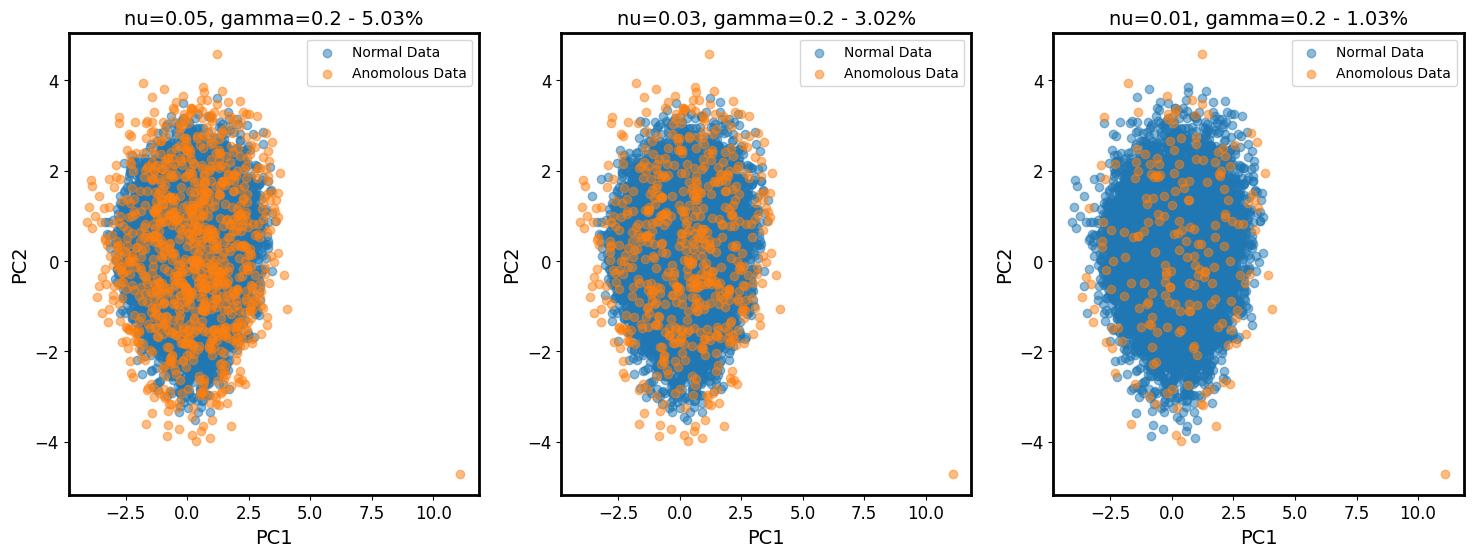

In [ ]:
# Visualise the reduced data in 2D.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))


for j in [1,-1]:
  axes[0].scatter(X_pca[y_pred1 == j, 0],
                X_pca[y_pred1 == j, 1],alpha=0.5)
  axes[1].scatter(X_pca[y_pred2 == j, 0],
                X_pca[y_pred2 == j, 1],alpha=0.5)
  axes[2].scatter(X_pca[y_pred3 == j, 0],
                X_pca[y_pred3 == j, 1],alpha=0.5)


  for i in range(3):
    axes[i].set_xlabel('PC1',fontsize=14)
    axes[i].set_ylabel('PC2',fontsize=14)
    axes[i].legend(labels=['Normal Data','Anomolous Data'])
    axes[i].tick_params(axis='both', which='major', labelsize=12)

    for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)


axes[0].set_title('nu=0.05, gamma=0.2 - 5.03%',fontsize=14)
axes[1].set_title('nu=0.03, gamma=0.2 - 3.02%',fontsize=14)
axes[2].set_title('nu=0.01, gamma=0.2 - 1.03%',fontsize=14)



#plt.savefig("OCSVD.png")
plt.show()


The PCA plots are represantative of the fact that a relatively low percentage of the full dataset constitutes outliers. However, the spread of the anomalous (orange) datapoints over the dense splash of (blue) normal datapoints is not indicative of a pattern between the normal and anomalous points. That said, even when the outlier percentage is reduced to nearly 1%, the densest portion of the anomalous points remains central which could be reflective of a pattern in real space.

In [ ]:
# Create a DataFrame to store explained variance:
df_variance = pd.DataFrame({
    'PC': range(1, len(pca.explained_variance_ratio_) + 1),
    'Explained Variance': pca.explained_variance_ratio_
})

# Print the DataFrame.
print(df_variance.to_string(index=False))

 PC  Explained Variance
  1            0.189948
  2            0.176930


Explained variance indicates the variance from the original data captured by each principal component. Thus, collectively only 37% of the variance in the dataset is captured by the principal components representing the axes in the above plots.  

## 4.Anomaly Detection Using Isolation Forest



* Isolation Forest is an ensemble technique which by treating anomalies as exceptions, can be said to work from the opposite direction to one-class SVM.

* Isolation Forest assumes that anomalies are few in number and are different, which means they can be isolated from the normal points in fewer steps or partitions of a decision tree.

* As random subsets of the dataset are drawn to build each (decision) tree in the forest, the data does not need to be scaled.

* Another advantage of the model is its computational efficiency.

### 4.1 Set-up Isolation Forest model to identify possible anomalies:

Isolation Forest has two parameters of interest:
* The number of estimators parameter -denoted n_estimators, which specifies the number of trees that will be built to form the forest.
* The contamination parameter which sets the expected ratio of anomalies to normal data points.

In [ ]:
# Function to perform Isolation Forest using different input parameters parameters
def apply_IsoForest(X,n_estimators, contamination):
  iso_forest = IsolationForest(n_estimators=n_estimators, contamination=contamination, random_state=42)
  iso_forest.fit(X)
  scores_pred = iso_forest.decision_function(X)
  y_pred = iso_forest.predict(X)
  df_iso= pd.DataFrame(X, columns=X.columns)
  df_iso['anomaly']=y_pred
  return y_pred, df_iso, scores_pred

In [ ]:
# Test Run
[y_pred, df_iso, scores_pred]=apply_IsoForest(df,100,0.1)
print(scores_pred)

[ 0.10138956 -0.05489974 -0.00345338 ...  0.02893474  0.09809211
  0.1105325 ]


The anomaly score is calculated based on the average path length required to isolate each data point across all trees in the forest, where a shorter path length or a lower score indicates a higher likelihood of a datapoint being an anomaly. Once again, the predictions made by the model are stored by the outcome variable, y_pred as 1s for normal datapoints and as -1s for anomalies.

In [ ]:
display(df_iso)

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,anomaly
0,682,2.391656,4.617196,2.848982,76.272417,69.884609,1
1,605,5.466877,6.424361,5.727520,73.222679,74.907314,-1
2,658,3.434232,3.680896,1.678708,88.089916,78.704806,-1
3,749,2.094656,7.120927,1.639670,77.661625,82.386700,1
4,676,3.538228,5.956472,3.225336,75.226352,67.153220,1
...,...,...,...,...,...,...,...
19530,681,3.598792,7.300853,1.083391,76.206955,69.848780,1
19531,580,2.243040,5.242489,1.471350,76.884907,87.098119,1
19532,616,3.310048,3.787693,6.001031,75.889810,72.220009,1
19533,1163,2.731726,3.703595,2.951684,76.784626,81.400088,1


### 4.2 Apply different combinations of parameter settings to improve the model's outlier predictions to the expected 1-5%:

In [ ]:
# Checking how the anomaly percentage varies with contamination parameter
# with n_estimator= 100

cont_list=[0.01,0.03,0.05,0.1,0.2]

for i in range(len(cont_list)):
  ypred, df_iso, _ = apply_IsoForest(df,100,cont_list[i])
  percentage=len(df_iso[df_iso['anomaly'] == -1])*100/len(df_iso)
  print('contamination =', cont_list[i],',', 'percentage of anomalies:','(', round(percentage,2),'%)')

contamination = 0.01 , percentage of anomalies: ( 1.0 %)
contamination = 0.03 , percentage of anomalies: ( 3.0 %)
contamination = 0.05 , percentage of anomalies: ( 5.0 %)
contamination = 0.1 , percentage of anomalies: ( 10.0 %)
contamination = 0.2 , percentage of anomalies: ( 20.0 %)


In [ ]:
# Checking how the anomaly percentage varies with n_estimator parameter
# with contamination=0.05 (5%)

nest_list=[50,100,200,500]

for i in range(len(nest_list)):
  ypred, df_iso, _ = apply_IsoForest(df,nest_list[i],0.05)
  percentage=len(df_iso[df_iso['anomaly'] == -1])*100/len(df_iso)

  print('n_estimators=', nest_list[i], 'percentage of anomalies:','(', round(percentage,2),'%)')

n_estimators= 50 percentage of anomalies: ( 5.0 %)
n_estimators= 100 percentage of anomalies: ( 5.0 %)
n_estimators= 200 percentage of anomalies: ( 5.0 %)
n_estimators= 500 percentage of anomalies: ( 5.0 %)


### 4.3 Visualise the output in 2D after performing PCA:

In [ ]:
# Run Isolation Forest with selected parameters first
# time it
start = time.time()
ypred1, df_iso1, _ = apply_IsoForest(df,100,0.05)
ypred2, df_iso2, _ = apply_IsoForest(df,100,0.03)
ypred3, df_iso3, _ = apply_IsoForest(df,100,0.01)
print((time.time() - start) * 1e3, "ms")

1819.9365139007568 ms


Based on the current timings, the Isolation Forest model is more than twice as fast compared to one-class SVM.

In [ ]:
# Merge the principal components with the OCSVM anomaly predictions.

df_pca_iso= pd.DataFrame(X_pca, columns=['PC1','PC2'], index=[''] * len(X_pca))

df_pca_iso['anomaly pred1']=ypred1
df_pca_iso['anomaly pred2']=ypred2
df_pca_iso['anomaly pred3']=ypred3

print(df_pca_iso)



         PC1       PC2  anomaly pred1  anomaly pred2  anomaly pred3
   -0.557362 -0.906512              1              1              1
   -2.177170 -1.201538             -1             -1              1
    2.051806  1.039581              1              1              1
    0.744375 -0.501140              1              1              1
   -1.629821 -0.473906              1              1              1
..       ...       ...            ...            ...            ...
   -1.311939  0.618409              1              1              1
    1.134547 -1.012464              1              1              1
   -0.832383 -2.159267              1              1              1
    1.126286 -0.051473              1              1              1
   -0.502369 -0.580875              1              1              1

[19535 rows x 5 columns]


Note that the Isolation Forest output is projected onto the same principal axes as one-class SVM, namely PC1 and PC2. While Isolation Forest does not require feature scaling, the principal components are still being drawn from the original 6-dimensional dataset post range-scaling.

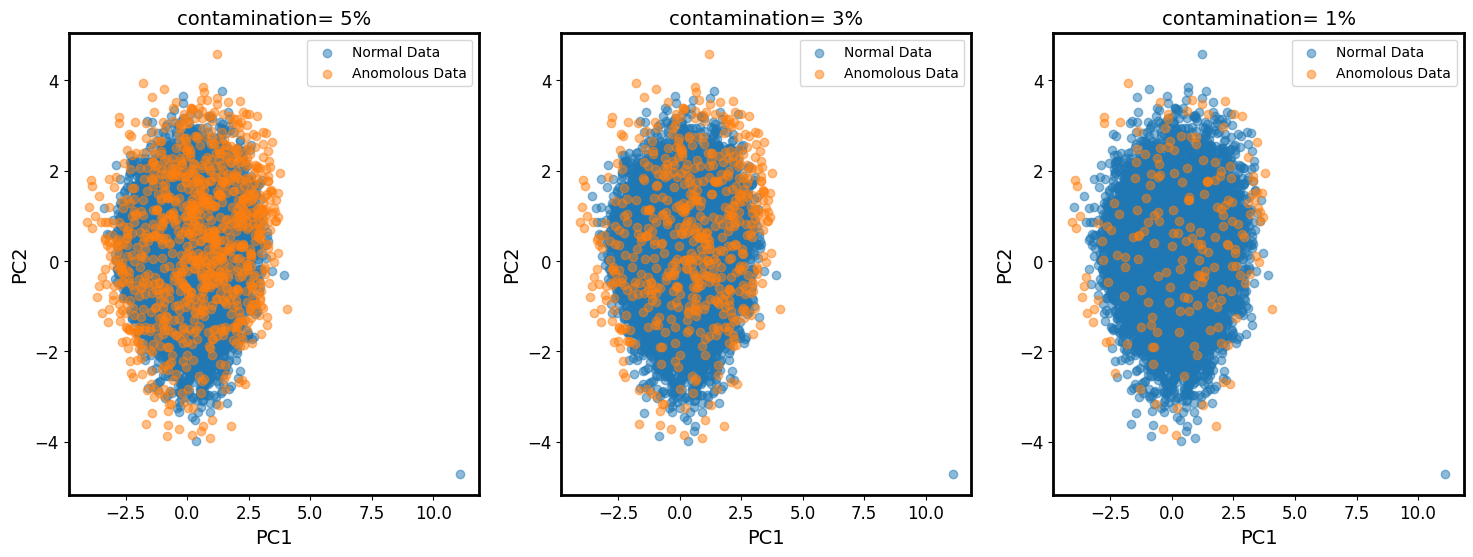

In [ ]:
# Visualise the reduced data in 2D.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))


for j in [1,-1]:
  axes[0].scatter(X_pca[ypred1 == j, 0],
                X_pca[ypred1 == j, 1],alpha=0.5)
  axes[1].scatter(X_pca[ypred2 == j, 0],
                X_pca[ypred2 == j, 1],alpha=0.5)
  axes[2].scatter(X_pca[ypred3 == j, 0],
                X_pca[ypred3 == j, 1],alpha=0.5)


  for i in range(3):
    axes[i].set_xlabel('PC1',fontsize=14)
    axes[i].set_ylabel('PC2',fontsize=14)
    axes[i].legend(labels=['Normal Data','Anomolous Data'])
    axes[i].tick_params(axis='both', which='major', labelsize=12)
    for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)

axes[0].set_title('contamination= 5%',fontsize=14)
axes[1].set_title('contamination= 3%',fontsize=14)
axes[2].set_title('contamination= 1%',fontsize=14)
#plt.savefig("IsoForest.png")
plt.show()


As before, no pattern can be inferred from the PCA plots. With decreasing contamination and hence anomaly percentage, the anomalous (orange) datapoints become better resolved from the normal (blue) datapoints. At the same time, predictions made by Isolation Forest seem to differ from those of one-class SVM. This discrepancy is most obvious in the case of the furthest point along the PC1 axis (blue point at the right-most corner), where at the 3% contamination level, the same point is marked as an outlier by one-class SVM and simultaneously marked as normal by Isolation Forest. At the 1% contamination level, the highest point along PC2 axis (blue point at the top-left) is also flipped to normal by the Isolation Forest algorithm. As the outermost points are more likely to be anomalies, this brings to question the accuracy of the model.

### 4.4 Can we improve model accuracy by using a higher value for n_estimator ?

To test this, the number of estimators are increased for the case of contamination= 1% and the model output is visualised in 2D using PCA.

In [ ]:
# Run Isolation Forest with different n_estimator settings
# with contamination set to 1%

ypred4, df_iso4, _ = apply_IsoForest(df,100,0.01)
ypred5, df_iso5, _ = apply_IsoForest(df,200,0.01)
ypred6, df_iso6, _ = apply_IsoForest(df,500,0.01)

In [ ]:
# Merge the principal components with the OCSVM anomaly predictions.


df_pca_iso['anomaly pred4']=ypred4
df_pca_iso['anomaly pred5']=ypred5
df_pca_iso['anomaly pred6']=ypred6

print(df_pca_iso)

         PC1       PC2  anomaly pred1  anomaly pred2  anomaly pred3  \
   -0.557362 -0.906512              1              1              1   
   -2.177170 -1.201538             -1             -1              1   
    2.051806  1.039581              1              1              1   
    0.744375 -0.501140              1              1              1   
   -1.629821 -0.473906              1              1              1   
..       ...       ...            ...            ...            ...   
   -1.311939  0.618409              1              1              1   
    1.134547 -1.012464              1              1              1   
   -0.832383 -2.159267              1              1              1   
    1.126286 -0.051473              1              1              1   
   -0.502369 -0.580875              1              1              1   

    anomaly pred4  anomaly pred5  anomaly pred6  
                1              1              1  
                1              1              1

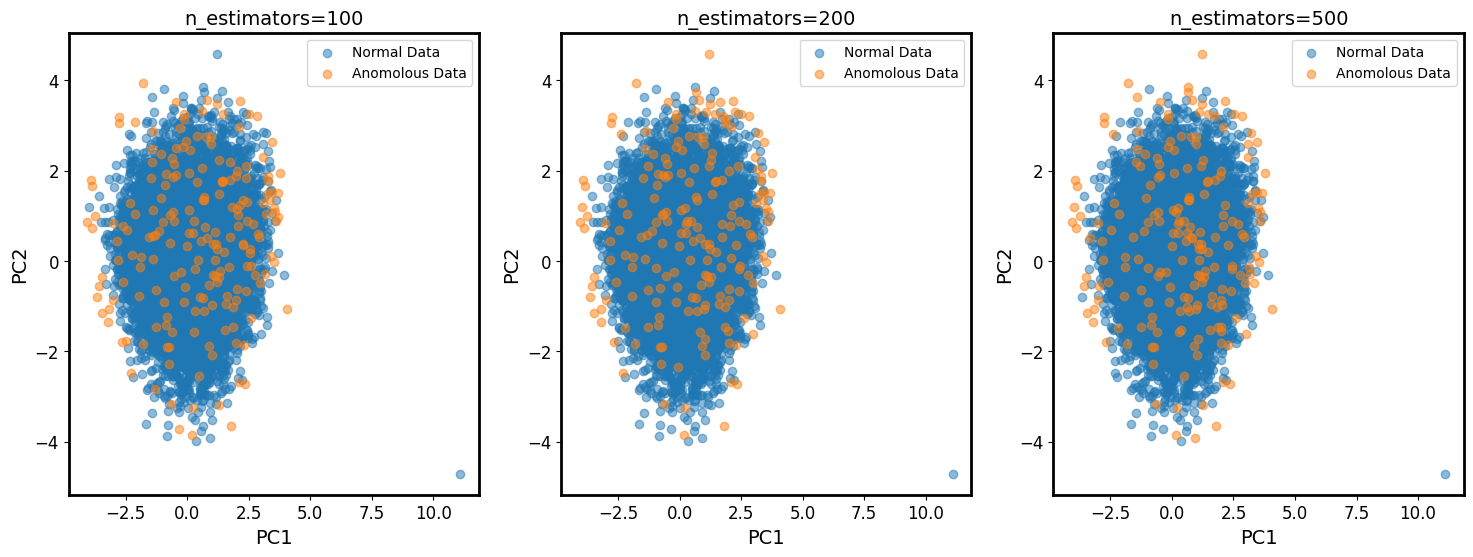

In [ ]:
# Visualise the reduced data in 2D.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))


for j in [1,-1]:
  axes[0].scatter(X_pca[ypred4 == j, 0],
                X_pca[ypred4 == j, 1],alpha=0.5)
  axes[1].scatter(X_pca[ypred5 == j, 0],
                X_pca[ypred5 == j, 1],alpha=0.5)
  axes[2].scatter(X_pca[ypred6 == j, 0],
                X_pca[ypred6 == j, 1],alpha=0.5)


  for i in range(3):
    axes[i].set_xlabel('PC1',fontsize=14)
    axes[i].set_ylabel('PC2',fontsize=14)
    axes[i].legend(labels=['Normal Data','Anomolous Data'])
    axes[i].tick_params(axis='both', which='major', labelsize=12)
    for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)

axes[0].set_title('n_estimators=100',fontsize=14)
axes[1].set_title('n_estimators=200',fontsize=14)
axes[2].set_title('n_estimators=500',fontsize=14)
#plt.savefig("IsoForest.png")
plt.show()

It can be seen that as the number of estimators are doubled, the top-most point along PC2 axis has been reverted back to an anomaly. When n_estimators is set to 500, the model output is not discernable form the case of n_estimators=200.

## 5.Summary and Conclusions:

A dataset containing 6 features critical to a ship engine's operational status has been analysed. The feature pre-processing involved checking for missing values and duplicates, of which none were found.

Next, it was confirmed through histogram plots (see section 1.7 of EDA) that none of the features fell under a normal distribution. The subsequent box plots showed a significant percentage of outliers were present for each feature, except the 'coolant temperature' which only had two points outside the maximum.

A statistical approach implementing IQR was used to flag datapoints in binary as outlined in sections 2.1 and 2.2. The total flag count obtained for each feature was found consistent with the picture painted by the box plots. A further analysis of outlier percentages, based on the number of features simultaneously flagged as outliers, indicated the expected anomaly threshold was satisfied *only when two features were simultaneously flagged as outliers*.

While the IQR approach produced realistic results where one flagged feature alone did not necessarily indicate an anomaly with a ship's engine, the process could be increasingly tedious for high-dimensional data due to manual implementation.

To detect anomalies in a more efficient way, two unsupervised ML techniques, namely one-class SVM and Isolation Forest were explored next. Following dimensionality reduction with PCA, the two model outputs were visualised in 2D and presented in section 4.3. In both cases, the PCA plots do not indicate a discernable pattern between the normal and anomalous data points. However, as anomaly percentage is decreased, the anomalous points become better resolved with the densest portion remaining centralised.

Moreover, the predictions made by the two ML models seem to differ which is most obvious in the case of two extreme points, one furthest along the PC1 axis and one highest along the PC2 axis. These points are classified as anomalous by the one-class SVM model while being simultaneously classified as normal by the Isolation Forest model. Due to the extreme nature of these two points (even when projected onto the principal axes), the one-class SVM model can be assumed to produce more accurate results, albeit at a significant computational cost.

As the Isolation Forest model performance also depends on the number of estimators used in the decision tree, the classification for one of the two extreme cases (but not the other) could be reversed by doubling the number of estimators (see section 4.4).

Due to the ambiguous nature of the PCA plots which account for only 37% of the total variance in the dataset, it is difficult to make a thorough assessment on the performance of the two ML models. That said, adding a third dimension to the PCA analysis could prove useful.


### References:
Devabrat, M., 2022. Predictive Maintenance on Ship's Main Engine using AI. Available at: https://dx.doi.org/10.21227/g3za-v415. [Accessed 5 March 2024]